# BYOC + data-centre flexibility (`BYOC_Flex`): validation of the constraints and comparison with `base_nodc` and `base_dc`

`BYOC_Flex` is the BYOC scenario (Bring Your Own Clean-energy: the data centres are served by **new renewables and storage only**, on top of the fixed `base_nodc` system, see `NOTEBOOK_BYOC`) with the **flexible data-centre load** switched on (`DCFLEX`, see `NOTEBOOK_Flexibility`). Its data and options are those of `BYOC`; the only difference in `balopt.opt` is `DCFLEX yes`, and the flexibility settings are in `BYOC_Flex/data/DC_FLEXPARAM.inc`.

1. **Validation of the BYOC constraints**: is the reference system fixed, are there no new fossil or nuclear investments, is the fossil fuel use within the `base_nodc` limit, is the decommissioning of the reference capacity switched off, is the transmission grid unchanged?
2. **Validation of the flexibility constraints**: are the shifting constraints of the data centres (Senga et al. 2026) met by the optimal solution, and do the flexible load and the electricity demand agree?
3. **Summary table**: system cost, CO2 emissions, marginal electricity cost and curtailment of `BYOC_Flex` compared with `base_nodc` and `base_dc`.

The constraints are tested on the **raw model data and decision variables** of the end-of-model file (`all_endofmodel.gdx`) and on the processed results (`MainResults*.gdx`), not only on the outputs. Each check has a tolerance and a PASS / FAIL status. The notebook only needs to be placed in the folder that contains `base_nodc`, `base_dc` and `BYOC_Flex`.

In [1]:
# 0.1 Settings, results of the three runs and helpers
from pathlib import Path
import re
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gams.transfer as gt
from IPython.display import display
from pybalmorel import MainResults

ROOT = Path.cwd() if (Path.cwd() / "BYOC_Flex").exists() else Path.cwd().parent       # folder containing the scenario folders
REFERENCE, BASE_DC, BYOC_FLEX = "base_nodc", "base_dc", "BYOC_Flex"
RUNS = {                                                                                  # label: (model folder, results file)
    REFERENCE: ("base_nodc/model", "MainResults_fullweek.gdx"),
    BASE_DC:   ("base_dc/model",   "MainResults_fullweek.gdx"),
    BYOC_FLEX: ("BYOC_Flex/model", "MainResults.gdx"),
}
RAW = {                                                                                   # raw end-of-model files (model data and decision variables)
    REFERENCE: "base_nodc/model/all_endofmodel_fullweek.gdx",
    BYOC_FLEX: "BYOC_Flex/model/all_endofmodel.gdx",
}
BYOC_DATA = ROOT / "BYOC_Flex" / "data"
OPTIONS = ROOT / "BYOC_Flex" / "model" / "balopt.opt"

res = {}
for run, (folder, file) in RUNS.items():
    if not (ROOT / folder / file).exists():
        raise FileNotFoundError(f"Results of {run} not found: {ROOT / folder / file}")
    res[run] = MainResults(files=file, paths=str(ROOT / folder), scenario_names=[run])

# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category",
          "SUBCATEGORY": "Subcategory", "UNITS": "Unit"}

def get(run, symbol):
    """Result symbol of one run as a DataFrame with standard column names and string years."""
    df = res[run].get_result(symbol).rename(columns=RENAME)
    return df[df["Scenario"] == run].assign(Year=lambda d: d["Year"].astype(str))

YEARS = sorted(set.intersection(*[set(get(run, "OBJ_YCR")["Year"]) for run in RUNS]), key=int)     # years solved in all runs
print(f"Years solved in all three runs: {', '.join(YEARS)}")

def read_raw(run, symbols):
    """Symbols of the end-of-model gdx of a run (model data and variables with their levels)."""
    if not (ROOT / RAW[run]).exists():
        raise FileNotFoundError(f"End-of-model file of {run} not found: {ROOT / RAW[run]}")
    c = gt.Container()
    c.read(str(ROOT / RAW[run]), symbols=symbols)
    return c

def raw_series(c, name, keys, column="level"):
    """Records of a variable (column 'level') or parameter (column 'value') as a Series indexed by `keys`; a symbol without records gives an empty Series."""
    t = c[name].records
    if t is None:
        return pd.Series(dtype=float)
    return t.assign(**{k: t[k].astype(str) for k in keys}).set_index(keys)[column]

checks = []                      # all validation checks of this notebook: dict(Section, Check, Test, Result, Tolerance, Status)
def add_check(section, check, test, result, tolerance, passed):
    checks.append({"Section": section, "Check": check, "Test": test, "Result": result, "Tolerance": tolerance, "Status": "PASS" if passed else "FAIL"})

def show_checks(section):
    """Table of the checks of one section; PASS green, FAIL red."""
    t = pd.DataFrame([c for c in checks if c["Section"] == section]).drop(columns="Section").set_index("Check")
    colour = lambda s: ["color: #1e8449; font-weight: bold" if v == "PASS" else "color: #c0392b; font-weight: bold" for v in s]
    display(t.style.apply(colour, subset=["Status"]).set_properties(**{"text-align": "left"}))

Loading /work3/s243704/Balmorel/base_nodc/model/MainResults_fullweek.gdx
Loading /work3/s243704/Balmorel/base_dc/model/MainResults_fullweek.gdx
Loading /work3/s243704/Balmorel/BYOC_Flex/model/MainResults.gdx
Years solved in all three runs: 2025, 2030, 2035


## 1. Validation of the BYOC constraints

Source of the constraints: `BYOC_Flex/data/BYOC_apply.inc`, `BYOC_settings.inc` and `BYOC_Flex/model/balopt.opt` (the same as for `BYOC`, see section 1 of `NOTEBOOK_BYOC`). Each constraint is tested against what the optimal solution of `BYOC_Flex` actually contains:

| # | Constraint | Test | PASS if |
|---|---|---|---|
| 1 | **Reference system is fixed** | The exogenous capacity `GKFX` of `BYOC_Flex` is compared with the net capacity of `base_nodc` (`GKFX + VGKNACCUMNET - VDECOM_EXO_ACCUM` of its end-of-model file, values below 1e-6 set to zero as in `BYOC_apply.inc`) for every area, generator and simulated year. | the largest difference is below the tolerance |
| 2 | **No new fossil or nuclear capacity** | The investment options `AGKN` and the investments `VGKN` are checked for all generators with a fuel in `BYOC_NONRENEWABLE_FUELS`. The new capacity of the other (renewable) generators is given for reference. | no investment option and no investment for these generators |
| 3 | **No extra fossil fuel use** | The annual use of every non-renewable fuel per region (`F_CONS_YCRA` of `BYOC_Flex`) is compared with the use of `base_nodc` times `1 + BYOC_FUELCAP_TOL`; the fuel limit is applied at the geographical level `BYOC_FUELCAP_LEVEL` (default `REGION`). | no region, fuel and year exceeds its limit |
| 4 | **Reference capacity is not decommissioned** | The options `NO_DECOM_EXO_G`, `LIFETIME_DECOM_EXO_G`, `ECONOMIC_DECOM_EXO_G` and `REVERT_DECOM_EXO_G` of `balopt.opt` (the last `$setglobal` counts) must be off, and the decommissioning of exogenous capacity in the solution (`VDECOM_EXO_ACCUM`) must be zero. | all options are off and the decommissioning is zero |
| 5 | **No transmission expansion** | `TransInvest` of `balopt.opt` must be `NO`, and the electricity transmission investments (`VXKN`, `VXKNACCUMNET`) in the solution must be zero. Hydrogen pipelines may be expanded (`H2TransInvest`). | the option is `NO` and there are no investments |

The fuel limit includes a small relative tolerance (`BYOC_FUELCAP_TOL`) so that the reference dispatch stays feasible; the check therefore allows `1e-6` TWh (1 MWh) on top of it for solver rounding. Years: all years solved in the three runs.

In [2]:
# 1.1 Validation of the BYOC constraints
TOL_CAP = 1e-6          # MW
TOL_FUEL = 1e-6         # TWh, on top of the relative tolerance of the fuel limit
settings = (BYOC_DATA / "BYOC_settings.inc").read_text()
options = OPTIONS.read_text()

def byoc_setting(name):
    return re.search(rf"\$setglobal\s+{name}\s+(\S+)", settings).group(1)

def option_value(name):
    """Value of a $setglobal option of balopt.opt: the last assignment counts; '' = the option is off."""
    found = re.findall(rf"^[ \t]*\$setglobal[ \t]+{name}\b[ \t]*(\S*)", options, flags=re.IGNORECASE | re.MULTILINE)
    found = [("" if v.startswith("*") else v) for v in found]
    return found[-1] if found else None

NONRENEWABLE = byoc_setting("BYOC_NONRENEWABLE_FUELS").split(",")
FUEL_TOL = float(byoc_setting("BYOC_FUELCAP_TOL"))
print(f"Fuel limit level: {byoc_setting('BYOC_FUELCAP_LEVEL')}, relative tolerance {FUEL_TOL}, {len(NONRENEWABLE)} non-renewable fuels: {', '.join(NONRENEWABLE)}")

ref, byoc = read_raw(REFERENCE, ["GKFX", "VGKNACCUMNET", "VDECOM_EXO_ACCUM"]), read_raw(BYOC_FLEX, ["GKFX", "AGKN", "IGF", "VGKN", "VDECOM_EXO_ACCUM", "VXKN", "VXKNACCUMNET"])

# --- 1. reference system is fixed
key3 = ["YYY", "AAA", "GGG"]
net = pd.concat([raw_series(ref, "GKFX", key3, "value").rename("gkfx"),
                 raw_series(ref, "VGKNACCUMNET", ["Y", "AAA", "G"]).rename_axis(key3).rename("accum"),
                 raw_series(ref, "VDECOM_EXO_ACCUM", ["Y", "AAA", "G"]).rename_axis(key3).rename("decom")], axis=1).fillna(0)
net = (net["gkfx"] + net["accum"] - net["decom"]).rename("reference")
net[net < 1e-6] = 0
used = pd.concat([net, raw_series(byoc, "GKFX", key3, "value").rename("BYOC_Flex")], axis=1).fillna(0)
used = used[used.index.get_level_values(0).isin(YEARS)]
max_diff = float((used["reference"] - used["BYOC_Flex"]).abs().max())
add_check("BYOC", "1. Reference system fixed", f"GKFX of BYOC_Flex = net capacity of base_nodc, {len(used):,} entries (area x generator x year)",
          f"max |difference| = {max_diff:.2e} MW", f"{TOL_CAP:.0e} MW", max_diff <= TOL_CAP)

# --- 2. no new fossil or nuclear capacity
fuel_of = byoc["IGF"].records
nonrenewable_gens = set(fuel_of.loc[fuel_of["FFF"].astype(str).isin(NONRENEWABLE), "GGG"].astype(str))
options_nonren = int(byoc["AGKN"].records["GGG"].astype(str).isin(nonrenewable_gens).sum())
invest = raw_series(byoc, "VGKN", ["Y", "AAA", "G"])
invest = invest[invest.index.get_level_values("Y").isin(YEARS)]
new_nonren = float(invest[invest.index.get_level_values("G").isin(nonrenewable_gens)].sum())
add_check("BYOC", "2. No new fossil or nuclear capacity", f"AGKN entries and VGKN investments of the {len(nonrenewable_gens):,} generators with a non-renewable fuel",
          f"{options_nonren} investment options, {new_nonren:.2e} MW built (new capacity of all other generators: {invest.sum() / 1e3:,.1f} GW)", "0", options_nonren == 0 and new_nonren <= TOL_CAP)

# --- 3. no extra fossil fuel use (region level, F_CONS_YCRA in TWh)
def fuel_use(run):
    t = get(run, "F_CONS_YCRA")
    t = t[t["Fuel"].astype(str).isin(NONRENEWABLE) & t["Year"].isin(YEARS)]
    return t.groupby(["Year", "Region", "Fuel"])["Value"].sum()

use = pd.concat([fuel_use(REFERENCE).rename("base_nodc"), fuel_use(BYOC_FLEX).rename("BYOC_Flex")], axis=1).fillna(0)
use["limit"] = use["base_nodc"] * (1 + FUEL_TOL)
use["excess"] = use["BYOC_Flex"] - use["limit"]
max_excess = float(use["excess"].max())
at_limit = int(((use["excess"].abs() <= TOL_FUEL) & (use["base_nodc"] > 0)).sum())
add_check("BYOC", "3. No extra fossil fuel use", f"BYOC_Flex use <= base_nodc use x (1 + {FUEL_TOL:g}), {len(use):,} combinations of region, fuel and year",
          f"max excess = {max_excess:.2e} TWh; {at_limit} combinations are exactly at the limit", f"{TOL_FUEL:.0e} TWh", max_excess <= TOL_FUEL)

# --- 4. reference capacity is not decommissioned
DECOM_OPTIONS = ["NO_DECOM_EXO_G", "LIFETIME_DECOM_EXO_G", "ECONOMIC_DECOM_EXO_G", "REVERT_DECOM_EXO_G"]
decom_values = {o: option_value(o) for o in DECOM_OPTIONS}
decom_on = [o for o, v in decom_values.items() if v]
decom = raw_series(byoc, "VDECOM_EXO_ACCUM", ["Y", "AAA", "G"])
decom_mw = float(decom.abs().sum()) if len(decom) else 0.0
add_check("BYOC", "4. Reference capacity not decommissioned", "balopt.opt: " + ", ".join(f"{o} = {'on (' + v + ')' if v else 'off'}" for o, v in decom_values.items()),
          f"{len(decom_on)} options on; decommissioned exogenous capacity (VDECOM_EXO_ACCUM) = {decom_mw:.2e} MW", "all off, 0 MW", not decom_on and decom_mw <= TOL_CAP)

# --- 5. no transmission expansion
trans_option = option_value("TransInvest")
trans = sum(float(raw_series(byoc, v, ["Y", "IRRRE", "IRRRI"]).abs().sum()) for v in ("VXKN", "VXKNACCUMNET"))
add_check("BYOC", "5. No transmission expansion", f"balopt.opt: TransInvest = {trans_option!r}; electricity transmission investments VXKN, VXKNACCUMNET",
          f"{trans:.2e} MW of new transmission (H2TransInvest = {option_value('H2TransInvest')!r}: hydrogen pipelines may expand)", "NO, 0 MW",
          (trans_option or "").upper() == "NO" and trans <= TOL_CAP)

show_checks("BYOC")

Fuel limit level: REGION, relative tolerance 0.0001, 24 non-renewable fuels: NUCLEAR, NATGAS, COAL, LIGNITE, FUELOIL, LIGHTOIL, HEAVYFUELOIL, ORIMULSION, SHALE, PEAT, MUNIWASTE, HAZARDOUSWASTE, LPG, LNG, OTHERGAS, RETORTGAS, COKE, COAL_EXETS, NATGAS_EXETS, FUELOIL_EXETS, LPG_EXETS, HEAVYFUELOIL_EXETS, COAL_CCS, NG_CCS


,Test,Result,Tolerance,Status
Check,,,,
1. Reference system fixed,"GKFX of BYOC_Flex = net capacity of base_nodc, 32,810 entries (area x generator x year)",max |difference| = 0.00e+00 MW,1e-06 MW,PASS
2. No new fossil or nuclear capacity,AGKN entries and VGKN investments of the 565 generators with a non-renewable fuel,"0 investment options, 0.00e+00 MW built (new capacity of all other generators: 111.5 GW)",0,PASS
3. No extra fossil fuel use,"BYOC_Flex use <= base_nodc use x (1 + 0.0001), 588 combinations of region, fuel and year",max excess = 2.07e-11 TWh; 155 combinations are exactly at the limit,1e-06 TWh,PASS
4. Reference capacity not decommissioned,"balopt.opt: NO_DECOM_EXO_G = off, LIFETIME_DECOM_EXO_G = off, ECONOMIC_DECOM_EXO_G = off, REVERT_DECOM_EXO_G = off",0 options on; decommissioned exogenous capacity (VDECOM_EXO_ACCUM) = 0.00e+00 MW,"all off, 0 MW",PASS
5. No transmission expansion,"balopt.opt: TransInvest = 'NO'; electricity transmission investments VXKN, VXKNACCUMNET",0.00e+00 MW of new transmission (H2TransInvest = 'YES': hydrogen pipelines may expand),"NO, 0 MW",PASS


## 2. Validation of the flexibility constraints

The flexible data-centre load follows Senga, Wang & Knittel (2026) (add-on `DCFLEX`, see `NOTEBOOK_Flexibility`). With the baseline load L<sub>t</sub> (flat, `IDCF_L`), the capacity C = `DC_CAPFACTOR` x peak L (`IDCF_C`), the share s = `DC_FLEXSHARE` and the shifting horizon h = `DC_SHIFTHORIZON`, the model has the variables Y<sub>t</sub> (backlog), S<sub>t</sub> (shifted load served) and D<sub>t</sub> (load deferred), and the constraints

| Equation | Constraint | Meaning |
|---|---|---|
| `QDCF_BAL` | Y<sub>t</sub> = Y<sub>t-1</sub> - S<sub>t</sub> + D<sub>t</sub> | backlog balance, circular within each season |
| `QDCF_DEFER` | sum of S over the next h steps >= Y<sub>t</sub> | a deferred load is served within h steps |
| `QDCF_ADV` | sum of D over the next h steps >= -Y<sub>t</sub> | an advanced load is offset within h steps |
| (bound) | D<sub>t</sub> <= s x L<sub>t</sub> | at most the share s of the load is deferred, so the load never falls below (1 - s) x L<sub>t</sub> |
| `QDCF_CAP` | S<sub>t</sub> - D<sub>t</sub> <= C - L<sub>t</sub> | the load after shifting never exceeds the capacity |

The data-centre load of the solution is L<sub>t</sub> - D<sub>t</sub> + S<sub>t</sub>. The cell below recomputes every constraint from the levels of `VDCF_Y`, `VDCF_S` and `VDCF_D` in the end-of-model file (with the forward window `IDCF_WINFWD` of the model) for every year, region, season and time step, and reports the worst slack. In addition it checks that the settings of `DC_FLEXPARAM.inc` are the ones used by the model, that the baseline load is the input data-centre load (`DE_DATACENTER.inc` / 8760), and that the load of the solution is the one that enters the electricity demand (the change in the `EXOGENOUS` demand relative to `base_nodc`, whose data-centre load is frozen at its 2025 value, as in Part 1 of `NOTEBOOK_Flexibility`).

In [3]:
# 2.1 Validation of the flexibility constraints
TOL_MW = 1e-3           # MW
TOL_MWH = 1e-2          # MWh
flex_text = (BYOC_DATA / "DC_FLEXPARAM.inc").read_text()
def flex_setting(name):
    return float(re.search(rf"SCALAR\s+{name}\s+'[^']*'\s*/\s*([0-9.eE+-]+)\s*/", flex_text).group(1))
SHARE, CAP_FACTOR, HORIZON = flex_setting("DC_FLEXSHARE"), flex_setting("DC_CAPFACTOR"), int(flex_setting("DC_SHIFTHORIZON"))
print(f"DC_FLEXPARAM.inc of BYOC_Flex: flexible share s = {SHARE:g}, capacity factor = {CAP_FACTOR:g}, shifting horizon h = {HORIZON} h")

dcf = read_raw(BYOC_FLEX, ["VDCF_Y", "VDCF_S", "VDCF_D", "IDCF_L", "IDCF_C", "IDCF_WINFWD"])
KEY = ["Y", "RRR", "S", "T"]
dc = pd.concat({"L": raw_series(dcf, "IDCF_L", KEY, "value"), "Y": raw_series(dcf, "VDCF_Y", KEY), "S": raw_series(dcf, "VDCF_S", KEY), "D": raw_series(dcf, "VDCF_D", KEY)}, axis=1).fillna(0).sort_index()
capacity = raw_series(dcf, "IDCF_C", ["Y", "RRR"], "value")
dc["C"] = capacity.reindex(dc.index.droplevel(["S", "T"])).values
dc["Load"] = dc["L"] - dc["D"] + dc["S"]                                              # data-centre load of the solution (MW)
steps = sorted(dc.index.get_level_values("T").unique())
step_nr = {t: i for i, t in enumerate(steps)}
window = np.zeros((len(steps), len(steps)))                                           # window[t, t'] = 1 if t' lies 1..h steps after t (circular within the season)
win = dcf["IDCF_WINFWD"].records
for a, b in zip(win["T"].astype(str), win["ITALIAS"].astype(str)):
    window[step_nr[a], step_nr[b]] = 1

# slack of every constraint per (year, region, season); positive = satisfied
rows = {}
for (year, region, season), x in dc.groupby(level=["Y", "RRR", "S"]):
    x = x.droplevel(["Y", "RRR", "S"]).reindex(steps)
    L, Y, S, D, C = x["L"].values, x["Y"].values, x["S"].values, x["D"].values, x["C"].iloc[0]
    load = L - D + S
    rows[(year, region, season)] = {
        "bal": np.abs(Y - np.roll(Y, 1) + S - D).max(),                               # QDCF_BAL residual (circular lag)
        "defer": (window @ S - Y).min(), "adv": (window @ D + Y).min(),               # QDCF_DEFER, QDCF_ADV slack
        "cap": (C - L - (S - D)).min(), "dmax": (SHARE * L - D).min(),                # QDCF_CAP and D <= s L
        "floor": (load - (1 - SHARE) * L).min(), "ceiling": (C - load).min(),         # load within [(1 - s) L, C]
        "energy": abs((S - D).sum())}                                                 # no net energy shifted over the season
slack = pd.DataFrame(rows).T
n_groups = len(slack)

per_step = window.sum(axis=1)
peak = dc.groupby(level=["Y", "RRR"])["L"].max()
cap_err = float((capacity - CAP_FACTOR * peak.reindex(capacity.index)).abs().max())
add_check("Flexibility", "Settings used by the model", f"window IDCF_WINFWD has h = {HORIZON} steps for every time step; IDCF_C = capacity factor x peak L ({len(capacity)} year-regions)",
          f"window sizes {int(per_step.min())}-{int(per_step.max())}; max |IDCF_C - {CAP_FACTOR:g} x peak L| = {cap_err:.2e} MW", f"{HORIZON}; {TOL_MW:g} MW",
          per_step.min() == per_step.max() == HORIZON and cap_err <= TOL_MW)

tests = [("QDCF_BAL: backlog balance", f"max |Y_t - Y_(t-1) + S_t - D_t|, {n_groups} year-region-seasons", "bal", "max", "MW"),
         ("QDCF_DEFER: deferred load served within h", "min (sum of S over the next h steps - Y_t)", "defer", "min", "MW"),
         ("QDCF_ADV: advanced load offset within h", "min (sum of D over the next h steps + Y_t)", "adv", "min", "MW"),
         ("QDCF_CAP: load after shifting <= C", "min (C - L_t - (S_t - D_t))", "cap", "min", "MW"),
         ("Deferral limit: D <= s x L", "min (s x L_t - D_t)", "dmax", "min", "MW"),
         ("Load floor: load >= (1 - s) x L", "min (load - (1 - s) x L_t)", "floor", "min", "MW"),
         ("Load ceiling: load <= C", "min (C - load)", "ceiling", "min", "MW"),
         ("Energy neutrality over each season", "max |sum of (S_t - D_t)| per season", "energy", "max", "MWh")]
for name, test, column, how, unit in tests:
    value = float(slack[column].max() if how == "max" else slack[column].min())
    tol = TOL_MWH if unit == "MWh" else TOL_MW
    add_check("Flexibility", name, test, f"{how} = {value:.2e} {unit}", f"{tol:g} {unit}", value <= tol if how == "max" else value >= -tol)

# input integrity: the baseline load is the annual data-centre load of the input / 8760
def read_gams_table(path):
    """Plain GAMS table (header row of years, then 'REGION v v v ...') as a DataFrame with the regions as index."""
    header, data = None, {}
    for line in Path(path).read_text(encoding="latin1").splitlines():
        tok = line.split()
        if len(tok) < 2 or line.lstrip().startswith("*"):
            continue
        if tok[0].isdigit():
            header = tok
        elif header and len(tok) == len(header) + 1:
            try:
                data[tok[0]] = [float(v) for v in tok[1:]]
            except ValueError:
                pass
    return pd.DataFrame(data, index=header).T

dc_input = read_gams_table(BYOC_DATA / "DE_DATACENTER.inc") / 8760                    # MW per region and year
expected = pd.Series([dc_input.loc[r, y] for y, r in dc.index.droplevel(["S", "T"])], index=dc.index)
input_err = float((dc["L"] - expected).abs().max())
add_check("Flexibility", "Baseline load = input data-centre load", f"IDCF_L vs. DE_DATACENTER.inc / 8760, {len(dc):,} year-region-hours",
          f"max |difference| = {input_err:.2e} MW", f"{TOL_MW:g} MW", input_err <= TOL_MW)

# link to the electricity demand: EXOGENOUS demand(BYOC_Flex) - EXOGENOUS demand(base_nodc) + data-centre load of base_nodc (2025 value, flat)
def exogenous_demand(run):
    folder, file = RUNS[run]
    c = gt.Container()
    c.read(str(ROOT / folder / file), symbols=["EL_DEMAND_YCRST"])
    t = c["EL_DEMAND_YCRST"].records
    t = t[t["VARIABLE_CATEGORY"].astype(str).eq("EXOGENOUS")]
    return t.assign(**{k: t[k].astype(str) for k in ("Y", "RRR", "SSS", "TTT")}).groupby(["Y", "RRR", "SSS", "TTT"])["value"].sum()

dc_nodc = read_gams_table(ROOT / "base_nodc" / "data" / "DE_DATACENTER.inc")["2025"] / 8760
exo = (exogenous_demand(BYOC_FLEX) - exogenous_demand(REFERENCE)).rename_axis(KEY).dropna()
exo = exo[exo.index.droplevel(["S", "T"]).isin(dc.index.droplevel(["S", "T"]).unique())]
from_demand = exo + dc_nodc.reindex(exo.index.get_level_values("RRR")).values
link_err = (from_demand - dc["Load"].reindex(from_demand.index)).abs()
add_check("Flexibility", "Load of the solution = load in the electricity demand", f"L - D + S vs. change in EXOGENOUS demand + data-centre load of base_nodc, {len(link_err):,} year-region-hours",
          f"max |difference| = {link_err.max():.2e} MW", f"{TOL_MW:g} MW", float(link_err.max()) <= TOL_MW)

show_checks("Flexibility")
used = dc.assign(Share=lambda d: d["Load"] / d["L"].where(d["L"] > 0))
print(f"Use of the flexibility: the load is below the baseline in {100 * (used['Share'] < 1 - 1e-6).mean():.0f} % and above it in {100 * (used['Share'] > 1 + 1e-6).mean():.0f} % of the region-hours; "
      f"minimum {max(used['Share'].min(), 0):.2f} x L, maximum {used['Share'].max():.2f} x L (bounds: {1 - SHARE:g} x L and {CAP_FACTOR:g} x L)")

DC_FLEXPARAM.inc of BYOC_Flex: flexible share s = 1, capacity factor = 1.25, shifting horizon h = 12 h


,Test,Result,Tolerance,Status
Check,,,,
Settings used by the model,window IDCF_WINFWD has h = 12 steps for every time step; IDCF_C = capacity factor x peak L (123 year-regions),window sizes 12-12; max |IDCF_C - 1.25 x peak L| = 0.00e+00 MW,12; 0.001 MW,PASS
QDCF_BAL: backlog balance,"max |Y_t - Y_(t-1) + S_t - D_t|, 492 year-region-seasons",max = 3.05e-11 MW,0.001 MW,PASS
QDCF_DEFER: deferred load served within h,min (sum of S over the next h steps - Y_t),min = -1.64e-11 MW,0.001 MW,PASS
QDCF_ADV: advanced load offset within h,min (sum of D over the next h steps + Y_t),min = -2.73e-11 MW,0.001 MW,PASS
QDCF_CAP: load after shifting <= C,min (C - L_t - (S_t - D_t)),min = -1.65e-12 MW,0.001 MW,PASS
Deferral limit: D <= s x L,min (s x L_t - D_t),min = -1.18e-11 MW,0.001 MW,PASS
Load floor: load >= (1 - s) x L,min (load - (1 - s) x L_t),min = -6.82e-12 MW,0.001 MW,PASS
Load ceiling: load <= C,min (C - load),min = -1.65e-12 MW,0.001 MW,PASS
Energy neutrality over each season,max |sum of (S_t - D_t)| per season,max = 5.46e-11 MWh,0.01 MWh,PASS


Use of the flexibility: the load is below the baseline in 21 % and above it in 78 % of the region-hours; minimum 0.00 x L, maximum 1.25 x L (bounds: 0 x L and 1.25 x L)


### Data-centre load of the solution against its bounds

Hourly data-centre load of `BYOC_Flex`, summed over all regions (GW), for each simulated season block of `PLOT_YEAR` (season blocks S10, S24, S40 and S50 are the modelled weeks; T001 = Monday 00:00). The baseline load L is flat; the solution has to stay between the floor (1 - s) x L (here 0, with a 100 % share) and the ceiling C = capacity factor x L (here 1.25 x L). Over each week the shifted energy sums to zero (energy neutrality).

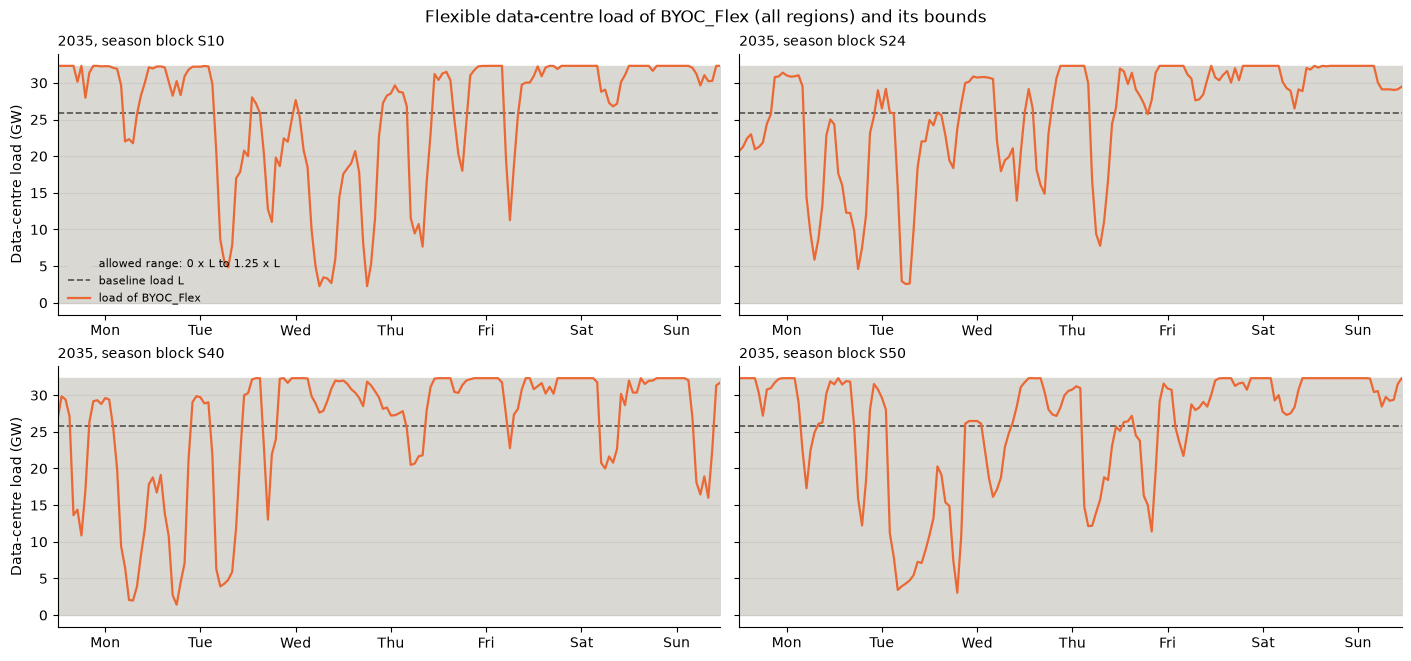

In [4]:
# 2.2 Data-centre load of the solution against its bounds (system total)
PLOT_YEAR = YEARS[-1]
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5), sharey=True, layout="constrained")
for ax, season in zip(axes.ravel(), sorted(dc.index.get_level_values("S").unique())):
    s = dc.xs((PLOT_YEAR, season), level=("Y", "S")).groupby(level="T").sum() / 1e3                # GW, all regions
    hour = np.arange(len(s))
    ax.fill_between(hour, (1 - SHARE) * s["L"], s["C"], color="#d9d8d2", label=f"allowed range: {1 - SHARE:g} x L to {CAP_FACTOR:g} x L")
    ax.plot(hour, s["L"], color="#52514e", lw=1.2, ls="--", label="baseline load L")
    ax.plot(hour, s["Load"], color="#eb6834", lw=1.6, label="load of BYOC_Flex")
    ax.set_title(f"{PLOT_YEAR}, season block {season}", loc="left", fontsize=10)
    ax.set_xlim(0, len(s) - 1)
    ax.set_xticks([24 * d + 12 for d in range(len(s) // 24)], ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][:len(s) // 24])
    ax.grid(axis="y", alpha=0.3)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Data-centre load (GW)")
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(f"Flexible data-centre load of BYOC_Flex (all regions) and its bounds")
plt.show()

### Validation summary

All checks of sections 1 and 2 in one table, with the overall result.

In [5]:
# 2.3 Validation summary
all_checks = pd.DataFrame(checks)
n_pass, n_fail = int((all_checks["Status"] == "PASS").sum()), int((all_checks["Status"] == "FAIL").sum())
display(all_checks.set_index(["Section", "Check"])[["Result", "Status"]].style.apply(
    lambda s: ["color: #1e8449; font-weight: bold" if v == "PASS" else "color: #c0392b; font-weight: bold" for v in s], subset=["Status"]).set_properties(**{"text-align": "left"}))
print(f"{n_pass} of {len(all_checks)} checks passed" + ("; all BYOC and flexibility constraints are met." if not n_fail else f"; FAILED: {', '.join(all_checks.loc[all_checks['Status'] == 'FAIL', 'Check'])}"))

16 of 16 checks passed; all BYOC and flexibility constraints are met.


## 3. Summary table: `BYOC_Flex` compared with `base_nodc` and `base_dc`

* **System cost**: `OBJ_YCR` (Mmoney). In BYOC the whole reference system is exogenous (cost-free) capacity, so the objective of `BYOC_Flex` holds the fixed O&M, variable O&M, fuel and CO2 cost of the entire system but **not the capital cost of the `base_nodc` investments**. As in `NOTEBOOK_BYOC` (section 2), the system cost of `BYOC_Flex` is therefore its objective plus the capital cost of `base_nodc` (`GENERATION_CAPITAL_COSTS`); adding the complete `base_nodc` cost would count the operating cost twice. The cell below shows the cost terms of the three runs and a consistency check.
* **CO2 emissions**: `EMI_YCRAG` (kton), total of all countries. `BYOC_Flex` dispatches the whole system, so its emissions are the system emissions.
* **Marginal electricity cost**: `EL_PRICE_YCR` (Money/MWh), time-averaged per region and weighted by the annual electricity demand of the region.
* **Curtailment**: onshore wind, offshore wind and solar, in TWh and as % of the available energy (dispatched + curtailed). Hydro rows of `CURT_YCRAGF` net to about zero and are left out, as in `NOTEBOOK_PostProcessing`.

The last columns give the difference of `BYOC_Flex` to `base_nodc` and to `base_dc`, in the unit of the metric and in % of the reference run (for the curtailment rate the % is a relative change, so see the TWh row for the absolute size).

In [6]:
# 3.1 Cost terms per run (Mmoney) and the system cost of BYOC_Flex
COST_GROUP = {
    "GENERATION_CAPITAL_COSTS": "Capital", "TRANSMISSION_CAPITAL_COSTS": "Capital", "H2_TRANSMISSION_CAPITAL_COSTS": "Capital",
    "GENERATION_FIXED_COSTS": "Fixed O&M",
    "GENERATION_OPERATIONAL_COSTS": "Variable O&M", "TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "GENERATION_FUEL_COSTS": "Fuel",
    "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2",
}
SUNK_IN_BYOC = ["GENERATION_CAPITAL_COSTS"]       # capital cost of the base_nodc investments, which are exogenous (cost-free) capacity in BYOC_Flex
SYSTEM_COST = "BYOC_Flex (system cost)"

cost = {run: get(run, "OBJ_YCR").groupby(["Year", "Category"])["Value"].sum().unstack("Category").fillna(0).reindex(YEARS, fill_value=0) for run in RUNS}
terms = pd.concat({run: cost[run].T for run in RUNS}, axis=1).fillna(0)
print("OBJ_YCR per cost term (Mmoney), as reported by each run")
display(terms.round(0))

byoc_corrected = cost[BYOC_FLEX].copy()
for term in SUNK_IN_BYOC:
    byoc_corrected[term] = byoc_corrected.get(term, 0) + cost[REFERENCE].get(term, 0)
cost[SYSTEM_COST] = byoc_corrected

total = pd.DataFrame({"base_nodc": cost[REFERENCE].sum(axis=1), "base_dc": cost[BASE_DC].sum(axis=1),
                      "BYOC_Flex objective only (reported)": cost[BYOC_FLEX].sum(axis=1),
                      "BYOC_Flex system cost (objective + base_nodc capital)": byoc_corrected.sum(axis=1)})
print("Total system cost (Mmoney)")
display(total.round(0))

# consistency check 1: in the first year the data-centre load is the same as in base_nodc (frozen at its 2025 level), so BYOC_Flex has no extra load.
# Its load is flexible, however, and flexibility can only lower the cost of the same load (the dispatch of base_nodc stays feasible), so its system cost must not exceed that of base_nodc.
first = YEARS[0]
diff0 = total.loc[first, "BYOC_Flex system cost (objective + base_nodc capital)"] - total.loc[first, "base_nodc"]
new_first = float(invest.xs(first, level="Y").sum()) / 1e3
print(f"Check ({first}, no extra data-centre load): new capacity of BYOC_Flex = {new_first:.2f} GW; system cost - base_nodc = {diff0:+,.1f} Mmoney ({diff0 / total.loc[first, 'base_nodc'] * 100:+.2f} %)"
      f"  -> {'consistent (flexibility can only lower the cost of the same load)' if diff0 <= 1e-6 * total.loc[first, 'base_nodc'] else 'CHECK: BYOC_Flex is more expensive than base_nodc for the same load'}")

# consistency check 2: the operating cost (everything except capital) must be of the size of base_dc, i.e. it contains the full system
capital = [c for c in cost[BYOC_FLEX].columns if COST_GROUP.get(c) == "Capital"]
operating = lambda c: c.drop(columns=capital, errors="ignore").sum(axis=1)
check = pd.DataFrame({"base_nodc": operating(cost[REFERENCE]), "base_dc": operating(cost[BASE_DC]), "BYOC_Flex": operating(cost[BYOC_FLEX])})
check["BYOC_Flex / base_dc (%)"] = check["BYOC_Flex"] / check["base_dc"] * 100
print("Operating cost (all terms except capital, Mmoney): BYOC_Flex is of the size of the full system, not of the data-centre part only")
display(check.round(1))

OBJ_YCR per cost term (Mmoney), as reported by each run


base_nodc                     base_dc  \
Year                                     2025     2030      2035     2025   
Category                                                                    
GENERATION_CAPITAL_COSTS              82955.0  92937.0  104813.0  82955.0   
GENERATION_CO2_TAX                    14063.0  14390.0   15488.0  14063.0   
GENERATION_CO2_TRANSPORT                340.0   1127.0    3276.0    340.0   
GENERATION_FIXED_COSTS                83261.0  86038.0   77482.0  83261.0   
GENERATION_FUEL_COSTS                 45599.0  42675.0   50169.0  45599.0   
GENERATION_OPERATIONAL_COSTS          13306.0  13528.0   13356.0  13306.0   
H2_TRANSMISSION_CAPITAL_COSTS             0.0    134.0     207.0      0.0   
H2_TRANSMISSION_OPERATIONAL_COSTS         0.0      0.0       0.0      0.0   
HEAT_TRANSMISSION_OPERATIONAL_COSTS       0.0      0.0       0.0      0.0   
TRANSMISSION_OPERATIONAL_COSTS            0.0      0.0       0.0      0.0   

                                                       BYOC_Flex           \
Year                                    2030      2035      2025     2030   
Category                                                                    
GENERATION_CAPITAL_COSTS             93319.0  107049.0      80.0    517.0   
GENERATION_CO2_TAX                   14583.0   15844.0   13623.0  14051.0   
GENERATION_CO2_TRANSPORT              1168.0    3487.0     340.0   1130.0   
GENERATION_FIXED_COSTS               86357.0   78423.0   83282.0  86181.0   
GENERATION_FUEL_COSTS                43166.0   51638.0   45187.0  42818.0   
GENERATION_OPERATIONAL_COSTS         13595.0   13537.0   13288.0  13532.0   
H2_TRANSMISSION_CAPITAL_COSTS          137.0     200.0       0.0    133.0   
H2_TRANSMISSION_OPERATIONAL_COSTS        0.0       0.0       0.0      0.0   
HEAT_TRANSMISSION_OPERATIONAL_COSTS      0.0       0.0       0.0      0.0   
TRANSMISSION_OPERATIONAL_COSTS           0.0       0.0       0.0      0.0   

                                              
Year                                    2035  
Category                                      
GENERATION_CAPITAL_COSTS              2357.0  
GENERATION_CO2_TAX                   15061.0  
GENERATION_CO2_TRANSPORT              3278.0  
GENERATION_FIXED_COSTS               78271.0  
GENERATION_FUEL_COSTS                51219.0  
GENERATION_OPERATIONAL_COSTS         13392.0  
H2_TRANSMISSION_CAPITAL_COSTS          215.0  
H2_TRANSMISSION_OPERATIONAL_COSTS        0.0  
HEAT_TRANSMISSION_OPERATIONAL_COSTS      0.0  
TRANSMISSION_OPERATIONAL_COSTS           0.0

Total system cost (Mmoney)


,base_nodc,base_dc,BYOC_Flex objective only (reported),BYOC_Flex system cost (objective + base_nodc capital)
Year,,,,
2025,239525.0,239525.0,155800.0,238755.0
2030,250830.0,252326.0,158362.0,251298.0
2035,264791.0,270178.0,163792.0,268604.0


Check (2025, no extra data-centre load): new capacity of BYOC_Flex = 2.12 GW; system cost - base_nodc = -769.9 Mmoney (-0.32 %)  -> consistent (flexibility can only lower the cost of the same load)
Operating cost (all terms except capital, Mmoney): BYOC_Flex is of the size of the full system, not of the data-centre part only


,base_nodc,base_dc,BYOC_Flex,BYOC_Flex / base_dc (%)
Year,,,,
2025,156569.4,156569.4,155720.0,99.5
2030,157759.2,158869.3,157711.3,99.3
2035,159771.0,162928.6,161220.3,99.0


In [7]:
# 3.2 Summary table
VRE_CURT_TECH = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]

def total_by_year(run, symbol, query=None):
    t = get(run, symbol)
    t = t.query(query) if query else t
    return t.groupby("Year")["Value"].sum().reindex(YEARS, fill_value=0)

def marginal_cost(run):
    # Demand-weighted average of EL_PRICE_YCR (Money/MWh) over the regions
    price = get(run, "EL_PRICE_YCR").query("Category == 'AVERAGE'").set_index(["Year", "Region"])["Value"]
    demand = get(run, "EL_DEMAND_YCR").groupby(["Year", "Region"])["Value"].sum()
    t = pd.concat({"P": price, "D": demand}, axis=1).dropna()
    return (t["P"] * t["D"]).groupby("Year").sum().div(t["D"].groupby("Year").sum()).reindex(YEARS)

def summary(run):
    vre = "Technology in @VRE_CURT_TECH and Commodity == 'ELECTRICITY'"
    curtailed, dispatched = total_by_year(run, "CURT_YCRAGF", vre), total_by_year(run, "PRO_YCRAGF", vre)
    system_cost = cost[SYSTEM_COST].sum(axis=1) if run == BYOC_FLEX else total_by_year(run, "OBJ_YCR")
    return pd.DataFrame({
        "System cost (Mmoney)": system_cost,
        "CO2 emissions (kton)": total_by_year(run, "EMI_YCRAG"),
        "Marginal electricity cost (Money/MWh)": marginal_cost(run),
        "Curtailment (TWh)": curtailed,
        "Curtailment (% of wind & solar available)": curtailed / (curtailed + dispatched).replace(0, np.nan) * 100,
    })

parts = {run: summary(run) for run in RUNS}
table = pd.concat({run: parts[run].T.stack() for run in RUNS}, axis=1)      # rows: metric x year
table.index = table.index.set_names(["Metric", "Year"])
table = table.reindex(list(parts[REFERENCE].columns), level="Metric")
for ref_run in (REFERENCE, BASE_DC):
    table[f"BYOC_Flex - {ref_run}"] = table[BYOC_FLEX] - table[ref_run]
    table[f"vs {ref_run} (%)"] = table[f"BYOC_Flex - {ref_run}"] / table[ref_run].replace(0, np.nan) * 100

def color_change(s):
    # red = BYOC_Flex is higher than the reference run, green = lower
    return ["color: #c0392b" if v > 0 else "color: #1e8449" if v < 0 else "" for v in s]

pct_cols = [f"vs {REFERENCE} (%)", f"vs {BASE_DC} (%)"]
styler = (table.style.format("{:,.2f}", subset=[REFERENCE, BASE_DC, BYOC_FLEX, f"BYOC_Flex - {REFERENCE}", f"BYOC_Flex - {BASE_DC}"])
          .format("{:+.2f} %", subset=pct_cols, na_rep="n/a")
          .apply(color_change, subset=pct_cols))
display(styler)